In [ ]:
import sys
sys.path.append("..")

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torch import cuda

import copy
import matplotlib.pyplot as plt

from src.data_cleaning import load_data
from src.models import create_logistic_regression, create_random_forest_search, MLP
from src.evaluation import (
    evaluate_model,
    select_threshold,
    plot_confusion_matrix,
    plot_precision_recall_curve,
    compare_models,
    plot_precision_recall_comparison
)

In [ ]:
RANDOM_STATE = 40

X, y = load_data()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

### Logistic Regression

In [ ]:
model_reg = create_logistic_regression(RANDOM_STATE)

model_reg.fit(X_train, y_train)

print(f"Number of iterations: {model_reg.n_iter_.max()}")

Number of iterations: 8


In [ ]:
print(sklearn.__version__)
print(model_reg.n_iter_.shape)
print(model_reg.Cs_)

1.9.0
(5, 1, 10)
[1.00000000e-04 7.74263683e-04 5.99484250e-03 4.64158883e-02
 3.59381366e-01 2.78255940e+00 2.15443469e+01 1.66810054e+02
 1.29154967e+03 1.00000000e+04]


In [ ]:
y_proba_val_logreg = model_reg.predict_proba(X_val)[:, 1]

threshold_logreg, val_metrics_logreg = select_threshold(
    y_val,
    y_proba_val_logreg,
    min_precision=0.5
)

if threshold_logreg is not None:
    print(f"Selected threshold: {threshold_logreg:.4f}")
    print(f"Validation precision: {val_metrics_logreg['precision']:.4f}")
    print(f"Validation recall: {val_metrics_logreg['recall']:.4f}")
else:
    print("No threshold satisfies the precision constraint.")

Selected threshold: 0.1518
Validation precision: 0.6364
Validation recall: 1.0000


In [ ]:
if threshold_logreg is not None:
    y_proba_logreg_all = model_reg.predict_proba(X_test)
    y_proba_logreg = y_proba_logreg_all[:, 1]

    y_pred_logreg = (y_proba_logreg >= threshold_logreg).astype(int)

    loss_logreg = sklearn.metrics.log_loss(
        y_test,
        y_proba_logreg_all
    )
    print(f"Test loss: {loss_logreg:.4f}")

    logreg_metrics = evaluate_model(
        y_test,
        y_pred_logreg,
        y_proba_logreg,
        loss=loss_logreg,
        threshold=threshold_logreg
    )

Test loss: 0.3155


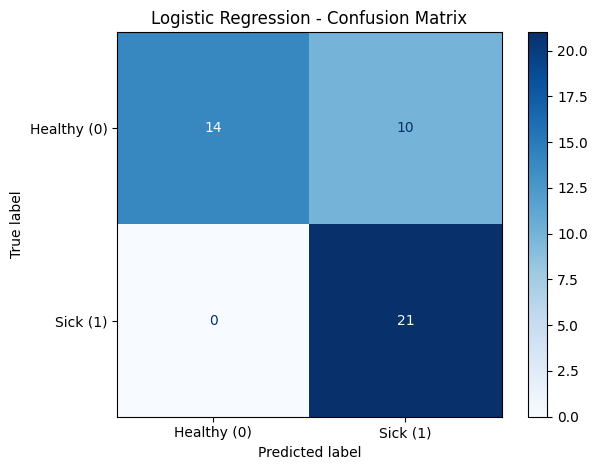

In [ ]:
plot_confusion_matrix(
    y_test,
    y_pred_logreg,
    "Logistic Regression"
)

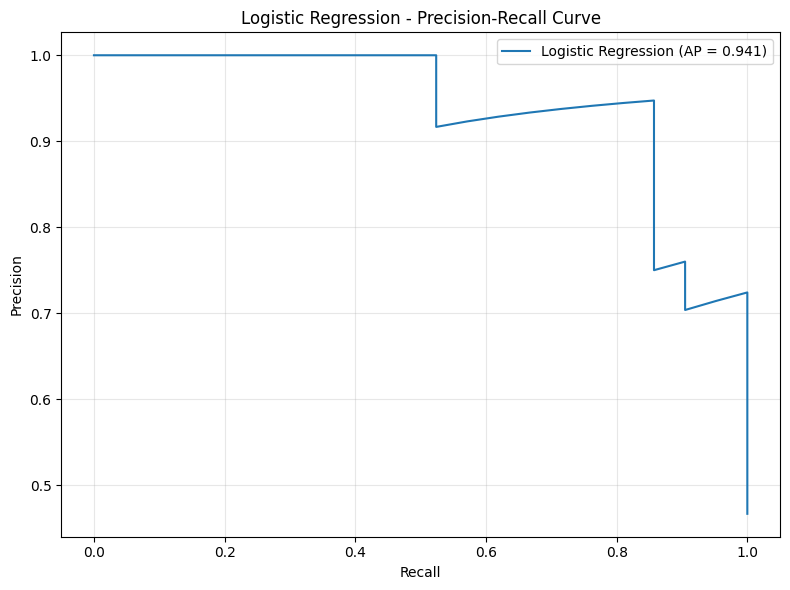

In [ ]:
logreg_curve = plot_precision_recall_curve(
    y_test,
    y_proba_logreg,
    "Logistic Regression"
)

### Random Forest

In [ ]:
grid = create_random_forest_search(RANDOM_STATE)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)
print("")

best_model = grid.best_estimator_

{'max_depth': 7, 'min_samples_split': 7, 'n_estimators': 50}
0.8315789473684211



In [ ]:
y_proba_val_rf = best_model.predict_proba(X_val)[:, 1]

threshold_rf, val_metrics_rf = select_threshold(
    y_val,
    y_proba_val_rf,
    min_precision=0.5
)

if threshold_rf is not None:
    print(f"Selected threshold: {threshold_rf:.4f}")
    print(f"Validation precision: {val_metrics_rf['precision']:.4f}")
    print(f"Validation recall: {val_metrics_rf['recall']:.4f}")
else:
    print("No threshold satisfies the precision constraint.")

Selected threshold: 0.1379
Validation precision: 0.5833
Validation recall: 1.0000


In [ ]:
if threshold_rf is not None:
    y_proba_rf_all = best_model.predict_proba(X_test)
    y_proba_rf = y_proba_rf_all[:, 1]

    y_pred_rf = (y_proba_rf >= threshold_rf).astype(int)

    loss_rf = sklearn.metrics.log_loss(y_test, y_proba_rf_all)
    print(f"Test loss: {loss_rf:.4f}")

    rf_metrics = evaluate_model(
        y_test,
        y_pred_rf,
        y_proba_rf,
        loss=loss_rf,
        threshold=threshold_rf
    )

Test loss: 0.3702


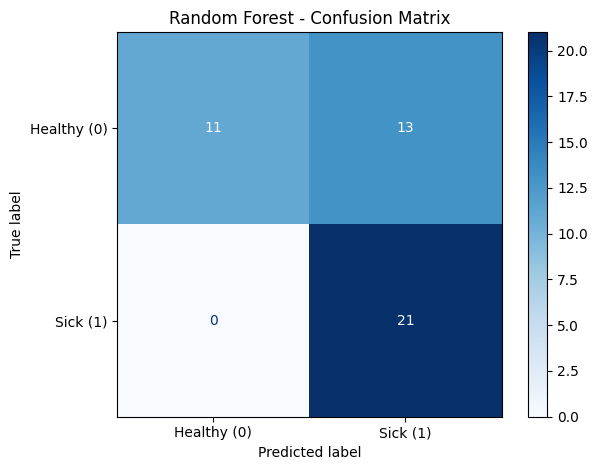

In [ ]:
plot_confusion_matrix(
    y_test,
    y_pred_rf,
    "Random Forest"
)

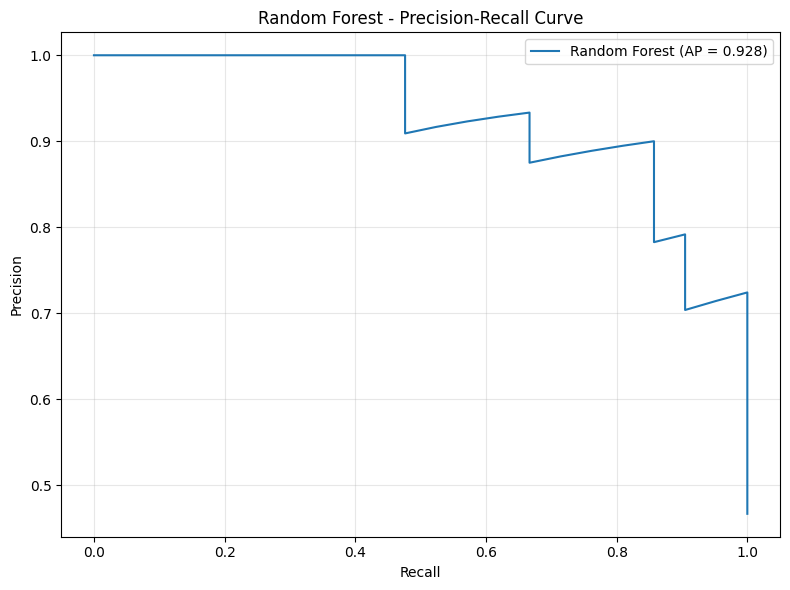

In [ ]:
rf_curve = plot_precision_recall_curve(
    y_test,
    y_proba_rf,
    "Random Forest"
)

### Multi-Layer Perceptron (MLP)

In [ ]:
BATCH_SIZE = 16
DROPOUT = 0.4
LEARNING_RATE = 5e-5
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-2
EPOCHS = 1500


device = "cuda" if cuda.is_available() else "cpu"
print(f"Current device: {device}")

Current device: cpu


In [ ]:
Xt_train = torch.tensor(X_train, dtype=torch.float32, device=device)
yt_train = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)

Xt_val = torch.tensor(X_val, dtype=torch.float32, device=device)
yt_val = torch.tensor(y_val.to_numpy(), dtype=torch.long, device=device)

Xt_test = torch.tensor(X_test, dtype=torch.float32, device=device)
yt_test = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)


in_features = Xt_train.shape[1]
out_features = len(torch.unique(yt_train))

train_dataset = TensorDataset(Xt_train, yt_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [ ]:
mlp_model = MLP(in_features, out_features, DROPOUT).to(device)
optimizer = torch.optim.Adam(
    params=mlp_model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=20
)
criterion = nn.CrossEntropyLoss()

In [ ]:
train_losses = []
val_losses = []

best_val_loss = float("inf")
best_weights = None
best_epoch = 0

for epoch in range(1, EPOCHS + 1):

    mlp_model.train()
    mean_train_loss = 0

    for Xt_batch, yt_batch in train_loader:

        yt_pred = mlp_model(Xt_batch)

        train_loss = criterion(yt_pred, yt_batch)
        mean_train_loss += (
            train_loss.item()
            * Xt_batch.shape[0]
            / len(train_loader.dataset)
        )

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

    mlp_model.eval()

    with torch.no_grad():
        yt_pred = mlp_model(Xt_val)
        val_loss = criterion(yt_pred, yt_val).item()
        scheduler.step(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch

    if epoch % 100 == 0:
        train_losses.append(mean_train_loss)
        val_losses.append(val_loss)

        print(f"Epoch: {epoch}")
        print(f"Train loss: {mean_train_loss:.4f}")
        print(f"Val loss: {val_loss:.4f}")
        print(f"Learning rate: {optimizer.param_groups[0]['lr']:.6f}")
        print("")

mlp_model.load_state_dict(best_weights)

print("")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch: 100
Train loss: 0.6247
Val loss: 0.6172
Learning rate: 0.000050

Epoch: 200
Train loss: 0.5090
Val loss: 0.4815
Learning rate: 0.000050

Epoch: 300
Train loss: 0.4589
Val loss: 0.4038
Learning rate: 0.000050

Epoch: 400
Train loss: 0.3920
Val loss: 0.3675
Learning rate: 0.000050

Epoch: 500
Train loss: 0.4184
Val loss: 0.3488
Learning rate: 0.000050

Epoch: 600
Train loss: 0.3608
Val loss: 0.3386
Learning rate: 0.000050

Epoch: 700
Train loss: 0.3579
Val loss: 0.3323
Learning rate: 0.000050

Epoch: 800
Train loss: 0.3878
Val loss: 0.3290
Learning rate: 0.000050

Epoch: 900
Train loss: 0.3609
Val loss: 0.3264
Learning rate: 0.000050

Epoch: 1000
Train loss: 0.3322
Val loss: 0.3249
Learning rate: 0.000025

Epoch: 1100
Train loss: 0.3574
Val loss: 0.3251
Learning rate: 0.000001

Epoch: 1200
Train loss: 0.3574
Val loss: 0.3251
Learning rate: 0.000000

Epoch: 1300
Train loss: 0.3516
Val loss: 0.3251
Learning rate: 0.000000

Epoch: 1400
Train loss: 0.3401
Val loss: 0.3251
Learning rat

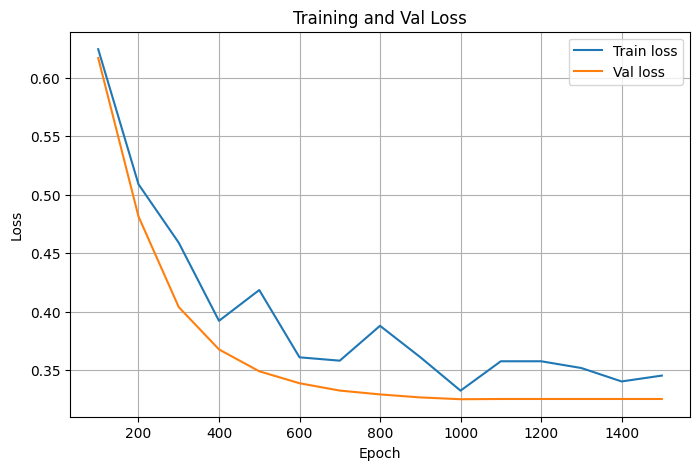

In [ ]:
epochs = range(100, EPOCHS + 1, 100)

# Graphe 1 : Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Val Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
mlp_model.eval()

with torch.no_grad():
    yt_pred_val = mlp_model(Xt_val)
    y_proba_val_mlp = torch.softmax(
        yt_pred_val, dim=1
    )[:, 1].cpu().numpy()

y_true_val_mlp = yt_val.cpu().numpy()

threshold_mlp, val_metrics_mlp = select_threshold(
    y_true_val_mlp,
    y_proba_val_mlp,
    min_precision=0.5
)

if threshold_mlp is not None:
    print(f"Selected threshold: {threshold_mlp:.4f}")
    print(f"Validation precision: {val_metrics_mlp['precision']:.4f}")
    print(f"Validation recall: {val_metrics_mlp['recall']:.4f}")
else:
    print("No threshold satisfies the precision constraint.")

Selected threshold: 0.2084
Validation precision: 0.7500
Validation recall: 1.0000


In [ ]:
if threshold_mlp is not None:
    mlp_model.eval()

    with torch.no_grad():
        yt_pred = mlp_model(Xt_test)
        mlp_loss = criterion(yt_pred, yt_test).item()

        y_true_mlp = yt_test.cpu().numpy()
        y_proba_mlp = torch.softmax(
            yt_pred, dim=1
        )[:, 1].cpu().numpy()

        y_pred_mlp = (
            y_proba_mlp >= threshold_mlp
        ).astype(int)

    print(f"Test loss: {mlp_loss:.4f}")

    mlp_metrics = evaluate_model(
        y_true_mlp,
        y_pred_mlp,
        y_proba_mlp,
        loss=mlp_loss,
        threshold=threshold_mlp
    )

Test loss: 0.3586


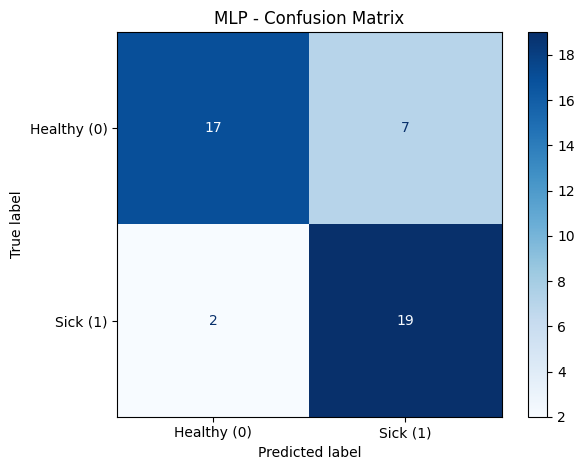

In [ ]:
plot_confusion_matrix(
    y_true_mlp,
    y_pred_mlp,
    "MLP"
)

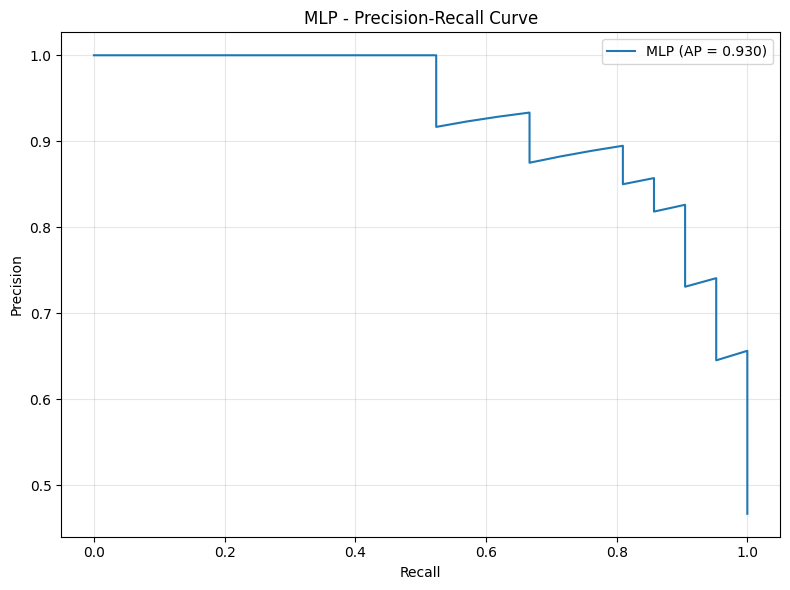

In [ ]:
mlp_curve = plot_precision_recall_curve(
    y_true_mlp,
    y_proba_mlp,
    "MLP"
)

### Model Comparison Overview

In [ ]:
model_metrics = {
    "Logistic Regression": logreg_metrics,
    "Random Forest": rf_metrics,
    "MLP": mlp_metrics
}

results = compare_models(model_metrics)
display(results.round(4))

,Threshold,Loss,Accuracy,Precision,Recall,F1-score,Average Precision
Model,,,,,,,
Logistic Regression,0.1518,0.3155,0.7778,0.6774,1.0000,0.8077,0.9407
Random Forest,0.1379,0.3702,0.7111,0.6176,1.0000,0.7636,0.9285
MLP,0.2084,0.3586,0.8000,0.7308,0.9048,0.8085,0.9301


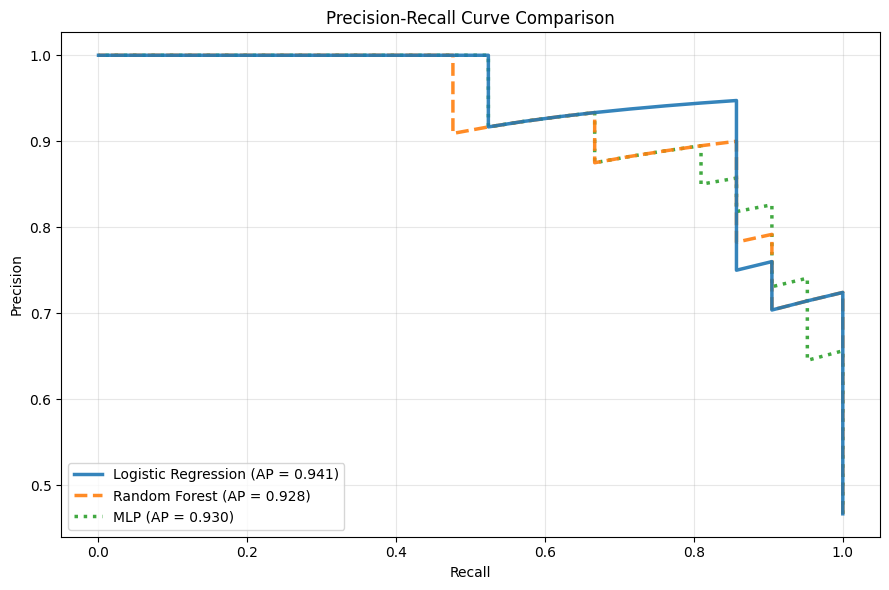

In [ ]:
curves = {
    "Logistic Regression": logreg_curve,
    "Random Forest": rf_curve,
    "MLP": mlp_curve
}

plot_precision_recall_comparison(curves)